# 01 — Исследование датасета

Первый взгляд на `dataset.parquet`: из чего состоит датасет, какие данные пригодны для модели,
и тепловые карты позиций на 90-й секунде боя.

Перед запуском: соберите датасет командой `python -m spawn_advisor.dataset` из корня проекта.

## 1. Загрузка

In [42]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data")

df = pd.read_parquet(DATA / "processed" / "dataset.parquet")
df.shape

(55671, 22)

In [43]:
df.head()

,arena_id,client_version,map_name,battle_type,gameplay_id,tank_id,player_name,vehicle_type,team,is_bot,...,x,z,alive_at_90,damage,assist_radio,spotted,kills,life_time,source,file
0,2306207056728478334,2.4.0.0,101_dday,1,ctf,539407618,puppelepee,uk:GB30_FV3805,1,False,...,-164.439148,-499.986176,True,637,0,0,1,388,bohdan,20261012_1528_japan-J41_Type_68_101_dday.wotre...
1,2306207056728478334,2.4.0.0,101_dday,1,ctf,539407620,mitra11,china:Ch22_113,1,False,...,-157.375687,27.480316,True,2234,271,3,0,247,bohdan,20261012_1528_japan-J41_Type_68_101_dday.wotre...
2,2306207056728478334,2.4.0.0,101_dday,1,ctf,539407621,n0life111,france:F37_AMX50_Foch,1,False,...,-378.452942,-421.462463,True,1680,0,1,2,388,bohdan,20261012_1528_japan-J41_Type_68_101_dday.wotre...
3,2306207056728478334,2.4.0.0,101_dday,1,ctf,539407624,TESLA_510,usa:A189_Ares_90,1,False,...,-439.272827,36.869682,False,115,32,4,0,52,bohdan,20261012_1528_japan-J41_Type_68_101_dday.wotre...
4,2306207056728478334,2.4.0.0,101_dday,1,ctf,539407625,Mortone,uk:GB130_FV225_Collector,1,False,...,32.695709,-79.721512,True,4785,89,1,2,388,bohdan,20261012_1528_japan-J41_Type_68_101_dday.wotre...


## 2. Из чего состоит датасет

Каждая ячейка — один вопрос к данным.

In [44]:
# Чьи реплеи: сколько строк из каждой папки data/raw/...
df["source"].value_counts()

source
web       44227
roma       6864
mine       2392
vlad       1693
bohdan      495
Name: count, dtype: int64

In [45]:
# Версии игры
df["client_version"].value_counts()

client_version
2.4.0.0        25383
2.4.1.0        22269
2.3.1.0         2873
2.1.0.0         1854
2.3.0.0         1152
2.0.1.0          845
2.1.1.0          491
2.2.1.0          225
2.2.0.0          180
1.28.0.0          60
0.9.15.1          60
2.0.0.0           59
1.29.0.0          45
1.29.1.0          30
0.9.17.0          30
1.18.1.0          15
1.25.1.0          15
1.26.1.0          15
1.24.1.0          15
1.26.0.0          15
1.27.1.0          15
1.28.1.0          15
0, 9, 14, 0       10
Name: count, dtype: int64

In [16]:
# Режимы: battle_type / gameplay_id. Для модели берём только 1 / ctf — стандартный случайный бой
df.groupby(["battle_type", "gameplay_id"]).size()

battle_type  gameplay_id  
1            ctf              14843
14           domination           2
20           domination        1022
27           epic               480
29           ctf                  9
38           maps_training        1
42           ctf                 28
43           comp7              630
44           ctf                 15
101          ctf                 80
102          ctf                 55
103          ctf                 20
dtype: int64

In [17]:
# Доли: среднее от колонки True/False — это доля True
df[["is_bot", "is_recorder", "alive_at_90", "won"]].mean()

is_bot         0.004772
is_recorder    0.075124
alive_at_90    0.956823
won            0.769799
dtype: float64

In [18]:
# Доля строк без позиции на 90-й секунде
df["x"].isna().mean()

np.float64(0.016875181844631947)

## 3. Данные для анализа позиций

Оставляем только:
- стандартный случайный бой (`battle_type == 1`, `gameplay_id == "ctf"`);
- живых людей: без ботов, живы на 90-й секунде, позиция известна.

`damage_rel` — урон танка, делённый на средний урон союзников в этом же бою.
`1.0` — средне для команды, `2.0` — вдвое больше. Так уровень танков и «урожайность» боя
почти не мешают сравнивать позиции.

In [46]:
standard = df[
    (df["battle_type"] == 1)
    & (df["gameplay_id"] == "ctf")
    & (~df["is_bot"])
    & (df["alive_at_90"])
    & (df["x"].notna())
].copy()

standard["damage_rel"] = standard["damage"] / standard.groupby("arena_id")["damage"].transform("mean")

print("строк:", len(standard), "боёв:", standard["arena_id"].nunique())

строк: 49882 боёв: 3501


In [20]:
# Сколько боёв за каждую команду (сторону спавна) — должно быть примерно поровну
standard.groupby("team")["arena_id"].nunique()

team
1    492
2    502
Name: arena_id, dtype: int64

In [47]:
# Самые частые карты: на них данных больше всего
standard["map_name"].value_counts().head(15)

map_name
05_prohorovka         2749
02_malinovka          2091
07_lakeville          1611
35_steppes            1458
18_cliff              1338
29_el_hallouf         1331
37_caucasus           1314
28_desert             1308
99_poland             1297
23_westfeld           1291
14_siegfried_line     1281
44_north_america      1268
34_redshire           1266
38_mannerheim_line    1261
08_ruinberg           1252
Name: count, dtype: int64

## 4. Тепловые карты

Две функции, чтобы строить графики для любой карты и стороны одной строкой.

In [22]:
def plot_positions(data, map_name):
    """Позиции на 90-й секунде: точка — танк, цвет — команда."""
    part = data[data["map_name"] == map_name]
    fig, ax = plt.subplots(figsize=(7, 7))
    for team, color in [(1, "tab:green"), (2, "tab:red")]:
        t = part[part["team"] == team]
        ax.scatter(t["x"], t["z"], s=12, alpha=0.6, c=color, label=f"команда {team} ({len(t)})")
    ax.set_aspect("equal")
    ax.set_xlim(-500, 500)
    ax.set_ylim(-500, 500)
    ax.set_xlabel("x (запад → восток)")
    ax.set_ylabel("z (юг → север)")
    ax.set_title(f"{map_name}: позиции на 90-й секунде")
    ax.legend()
    plt.show()


def plot_damage_heatmap(data, map_name, team, gridsize=12, mincnt=3):
    """Две карты рядом: сколько танков в зоне и их средний относительный урон."""
    part = data[(data["map_name"] == map_name) & (data["team"] == team)]
    extent = (-500, 500, -500, 500)
    fig, (ax_count, ax_dmg) = plt.subplots(1, 2, figsize=(14, 7))

    hb_count = ax_count.hexbin(part["x"], part["z"], gridsize=gridsize, extent=extent, mincnt=1, cmap="Blues")
    fig.colorbar(hb_count, ax=ax_count, label="танков в зоне")
    ax_count.set_title("Сколько танков (надёжность зоны)")

    hb_dmg = ax_dmg.hexbin(
        part["x"], part["z"], C=part["damage_rel"],
        reduce_C_function=np.mean, gridsize=gridsize, mincnt=mincnt,
        extent=extent, cmap="RdYlGn", vmin=0.3, vmax=1.7,
    )
    fig.colorbar(hb_dmg, ax=ax_dmg, label="урон относительно среднего по команде")
    ax_dmg.set_title(f"Средний относительный урон (зоны от {mincnt} танков)")

    for ax in (ax_count, ax_dmg):
        ax.set_aspect("equal")
        ax.set_xlabel("x (запад → восток)")
        ax.set_ylabel("z (юг → север)")
    fig.suptitle(f"{map_name}, команда {team}: {part['arena_id'].nunique()} боёв, {len(part)} танков")
    plt.show()

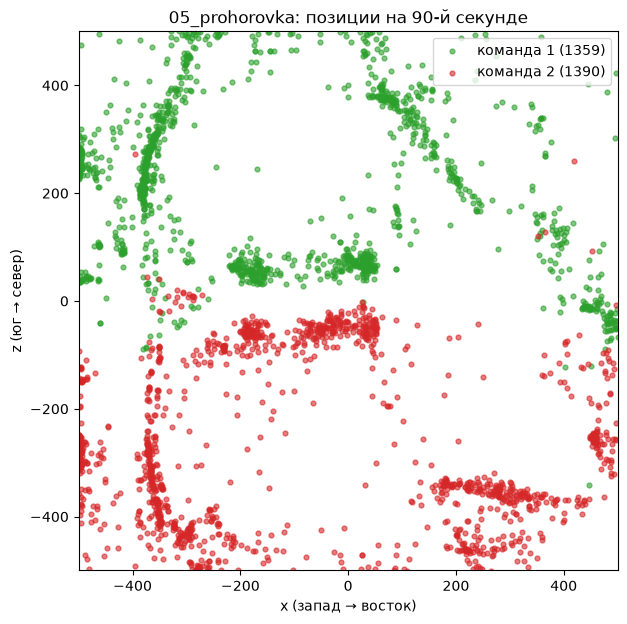

In [50]:
plot_positions(standard, "05_prohorovka")

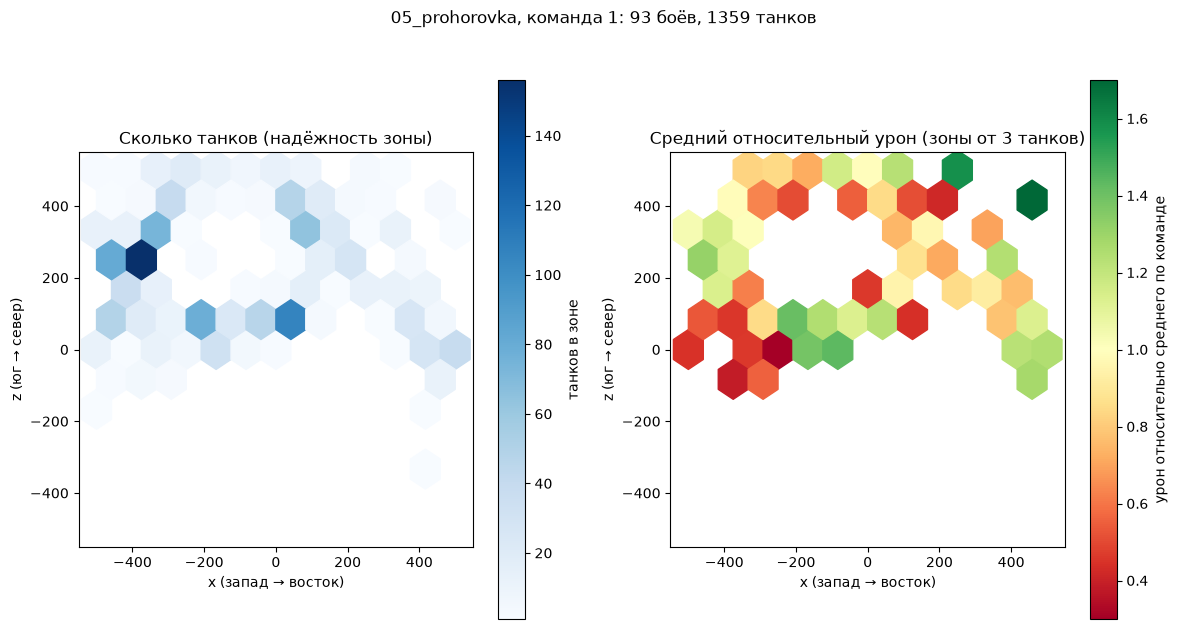

In [51]:
plot_damage_heatmap(standard, "05_prohorovka", team=1)

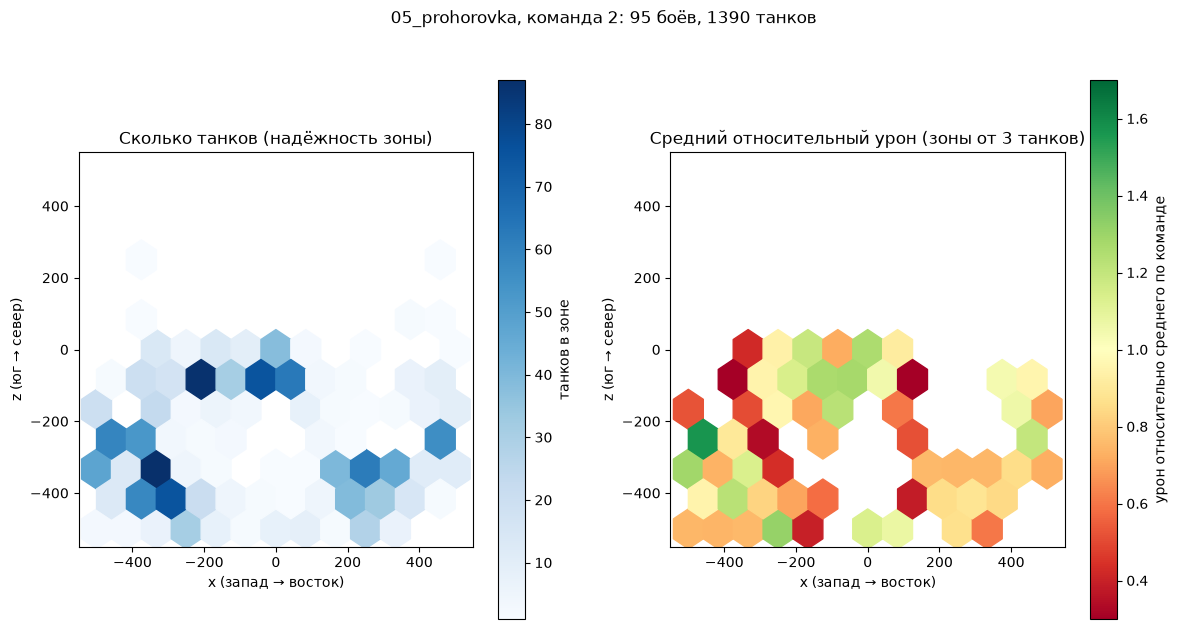

In [52]:
plot_damage_heatmap(standard, "05_prohorovka", team=2)

## 5. Пропущенные реплеи

`skipped.csv` пишет `build_dataset`: какие файлы не попали в датасет и почему.

In [26]:
skipped = pd.read_csv(DATA / "processed" / "skipped.csv")
skipped.groupby(["source", "reason"]).size()

source  reason                        
bohdan  нет результатов или старта боя     21
mine    нет результатов или старта боя    277
roma    нет результатов или старта боя     11
vlad    нет результатов или старта боя    133
web     не реплей WoT                      31
dtype: int64

In [27]:
# JSON-заголовок читается у любой версии — узнаём версию, режим и есть ли результаты
from spawn_advisor.replay.container import read_replay_file

info = []
for _, row in skipped.iterrows():
    path = DATA / "raw" / row["source"] / row["file"]
    try:
        replay = read_replay_file(path)
    except Exception as error:
        info.append({"file": row["file"], "source": row["source"], "version": "ошибка чтения",
                     "mode": str(error), "has_results": None})
        continue
    header = replay.header
    info.append({
        "file": row["file"],
        "source": row["source"],
        "version": header.get("clientVersionFromExe"),
        "mode": f'{header.get("battleType")}/{header.get("gameplayID")}',
        "has_results": replay.results is not None,
    })

info = pd.DataFrame(info)
info.groupby(["source", "version", "mode", "has_results"]).size()

source  version  mode           has_results
bohdan  2.4.0.0  1/ctf          False          14
        2.4.1.0  1/ctf          False           7
mine    2.0.0.0  43/comp7       False           1
        2.0.1.0  1/ctf          False           7
                 101/ctf        False           3
                 103/ctf        False           1
                 14/domination  False           1
                 29/ctf         False           9
                 43/comp7       False          67
        2.1.0.0  1/ctf          False          84
        2.1.1.0  43/comp7       False          10
        2.3.1.0  1/ctf          False          28
        2.4.0.0  1/ctf          False          41
                 43/comp7       False          15
                 44/ctf         False           1
        2.4.1.0  1/ctf          False           9
roma    2.3.1.0  1/ctf          False           1
        2.4.0.0  1/ctf          False           6
        2.4.1.0  1/ctf          False           4
vlad  

In [28]:
# Главное: досиженные стандартные бои, которые всё равно пропущены.
# Если тут не пусто — парсер не справляется с этими файлами, и это повод разбираться.
lost = info[(info["mode"] == "1/ctf") & (info["has_results"] == True)]
lost.groupby(["source", "version"]).size()

Series([], dtype: int64)

## 6. Отладка: поиск старта боя в старой версии

Так мы нашли, что в 2.3 метод периодов боя имеет номер 59, а в 2.4 — 58.
Если новая версия игры перестанет читаться, начинать отсюда:
подставьте в `debug_file` пропущенный файл и посмотрите, найдётся ли кортеж `(3, ..., 900, ...)`.

In [29]:
import io
import struct
import zlib

from spawn_advisor.replay.battle import SafeUnpickler
from spawn_advisor.replay.crypto import decrypt_packet_stream
from spawn_advisor.replay.packets import read_packets

debug_file = DATA / "raw" / "roma" / "20260716_0141_uk-GB158_Executor_28_desert.wotreplay"

replay = read_replay_file(debug_file)
packets = read_packets(decrypt_packet_stream(replay.encrypted))
print(debug_file.name, "| версия", replay.header["clientVersionFromExe"], "| пакетов:", len(packets))

for packet in packets:
    if packet.type != 8 or len(packet.payload) < 15 or packet.payload[12] != 3:
        continue
    method_id, = struct.unpack("<I", packet.payload[4:8])
    try:
        value = SafeUnpickler(io.BytesIO(zlib.decompress(packet.payload[14:]))).load()
    except Exception:
        continue
    print(round(packet.time, 2), method_id, value)

20260716_0141_uk-GB158_Executor_28_desert.wotreplay | версия 2.3.1.0 | пакетов: 173144
0.0 59 (1, 64548.4, 60.0, (1, 1))
0.0 59 (2, 64527.2, 30, [])
28.76 59 (3, 65427.2, 900, [])
544.86 59 (4, 65103.3, 60.0, (1, 1))


In [31]:
df.groupby("client_version")["x"].apply(lambda s: s.isna().mean())

client_version
1.27.1.0    0.000000
1.28.0.0    0.000000
1.28.1.0    0.000000
2.0.0.0     0.000000
2.0.1.0     0.043373
2.1.0.0     0.000000
2.1.1.0     0.000000
2.2.0.0     0.000000
2.2.1.0     0.047619
2.3.0.0     0.000000
2.3.1.0     0.000000
2.4.0.0     0.000000
2.4.1.0     0.038749
Name: x, dtype: float64

In [32]:
df.groupby("client_version")[["x", "z"]].describe().round(0)

x                                                     \
                 count   mean    std     min    25%    50%    75%     max   
client_version                                                              
1.27.1.0          15.0  -68.0  277.0  -359.0 -304.0 -266.0  212.0   338.0   
1.28.0.0          30.0  251.0  259.0  -255.0  111.0  274.0  463.0   591.0   
1.28.1.0          15.0  -57.0  256.0  -490.0 -200.0   -3.0  120.0   215.0   
2.0.0.0           14.0   82.0   65.0    -2.0   56.0   77.0   98.0   259.0   
2.0.1.0          794.0   55.0  310.0  -881.0 -170.0   16.0  262.0  1401.0   
2.1.0.0         1719.0  -19.0  255.0  -515.0 -239.0  -13.0  181.0   595.0   
2.1.1.0          386.0    4.0  253.0  -509.0 -195.0   -2.0  177.0   599.0   
2.2.0.0          135.0   50.0  282.0  -487.0 -202.0   71.0  329.0   492.0   
2.2.1.0          100.0   37.0  235.0  -396.0 -106.0   37.0  225.0   495.0   
2.3.0.0          987.0    9.0  263.0  -500.0 -216.0   12.0  217.0   507.0   
2.3.1.0         2094.0  -15.0  275.0  -526.0 -258.0  -15.0  216.0   589.0   
2.4.0.0         4429.0  -19.0  265.0  -500.0 -251.0  -18.0  198.0   596.0   
2.4.1.0         6177.0  -15.0  303.0 -1399.0 -257.0  -12.0  207.0  1456.0   

                     z                                                     
                 count   mean    std     min    25%    50%    75%     max  
client_version                                                             
1.27.1.0          15.0 -160.0  145.0  -387.0 -280.0 -140.0  -28.0     5.0  
1.28.0.0          30.0   81.0  249.0  -430.0    7.0  135.0  243.0   489.0  
1.28.1.0          15.0  231.0  170.0    35.0   82.0  185.0  399.0   483.0  
2.0.0.0           14.0  133.0  127.0    -5.0   35.0  132.0  192.0   468.0  
2.0.1.0          794.0  -71.0  309.0 -1034.0 -247.0  -29.0  139.0  1448.0  
2.1.0.0         1719.0   14.0  239.0  -561.0 -147.0   13.0  192.0   587.0  
2.1.1.0          386.0   11.0  245.0  -557.0 -168.0   16.0  196.0   535.0  
2.2.0.0          135.0  -44.0  227.0  -500.0 -198.0  -78.0  103.0   489.0  
2.2.1.0          100.0 -151.0  216.0  -495.0 -312.0 -162.0  -60.0   432.0  
2.3.0.0          987.0   -2.0  257.0  -535.0 -202.0   16.0  194.0   546.0  
2.3.1.0         2094.0   -4.0  256.0  -547.0 -202.0   -9.0  201.0   540.0  
2.4.0.0         4429.0   10.0  242.0  -570.0 -155.0   17.0  188.0   662.0  
2.4.1.0         6177.0  -10.0  301.0 -1480.0 -201.0   12.0  205.0  1214.0

In [49]:
df.groupby("source")["won"].mean()

source
bohdan    0.818182
mine      0.866639
roma      0.683275
vlad      0.854105
web       0.818844
Name: won, dtype: float64

In [34]:
big = df[(df["x"].abs() > 600) | (df["z"].abs() > 600)]
big["gameplay_id"].value_counts()

gameplay_id
epic    199
ctf      49
Name: count, dtype: int64

In [35]:
df.groupby("gameplay_id")["x"].apply(lambda s: s.isna().mean())

gameplay_id
comp7            0.000000
ctf              0.000797
domination       0.000977
epic             0.577083
maps_training    0.000000
Name: x, dtype: float64